## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = True
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)
device

device(type='cuda')

In [2]:
## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [3]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [4]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [5]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

In [6]:
def interval_linear(lo, hi, W, b):
    c, r = (lo + hi) / 2, (hi - lo) / 2
    c = c @ W.T + b
    r = r @ W.abs().T
    return c - r, c + r

def interval_relu(lo, hi):
    return lo.clamp(min=0), hi.clamp(min=0)

In [7]:
def interval_analysis(model, x, y, eps):
    """Returns boolean tensor: True if image is robust"""
    norm, net = model[0], model[1]
    W1, b1 = net.fc.weight, net.fc.bias
    W2, b2 = net.fc2.weight, net.fc2.bias

    # eps-ball
    lo = (x - eps).clamp(0, 1).view(-1, 28*28)
    hi = (x + eps).clamp(0, 1).view(-1, 28*28)

    # Normalize
    lo, hi = norm(lo), norm(hi)

    lo, hi = interval_linear(lo, hi, W1, b1)
    lo, hi = interval_relu(lo, hi)
    # lo, hi = interval_linear(lo, hi, W2, b2)
    # find difference first, keep relationship
    Wd = W2[y].unsqueeze(1) - W2.unsqueeze(0)   # (input_size, # classes, # neurons)
    bd = b2[y].unsqueeze(1) - b2.unsqueeze(0)   # (input_size, # classes)

    c, r = (lo + hi) / 2, (hi - lo) / 2         # (input_size, # neurons)
    # center of image i, class j = sum_{all neorons k} (Wd[i,j,k] * c[i,k] + bd[i,j]), where
    # Wd[ijk] := weight difference of image i, class j, neuron k
    # c[bk] := center of image i, neuron k
    # bd[i,j] := bias of image i, class j
    c_out = torch.einsum('ijk,ik->ij', Wd, c) + bd
    r_out = torch.einsum('ijk,ik->ij', Wd.abs(), r)
    lower = c_out - r_out

    # lower < 0 means class y - class j < 0, which means fail
    return (lower >= 0).all(dim=1)

In [10]:
def verified_accuracy(model, eps):
    model.eval()
    verified = 0
    total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            verified += interval_analysis(model, x, y, eps).sum().item()
            total += y.size(0)
    return 100 * verified / total

epsilons = np.linspace(0.01, 0.1, 10)
results = []
for eps in epsilons:
    acc = verified_accuracy(model, eps)
    results.append(acc)
    print(f"eps = {eps:.2f}: {acc:.2f}% of inputs can be proven robust, the rest cannot be proven anything")

eps = 0.01: 70.55% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.02: 23.68% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.03: 4.56% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.04: 0.58% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.05: 0.02% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.06: 0.00% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.07: 0.00% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.08: 0.00% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.09: 0.00% of inputs can be proven robust, the rest cannot be proven anything
eps = 0.10: 0.00% of inputs can be proven robust, the rest cannot be proven anything


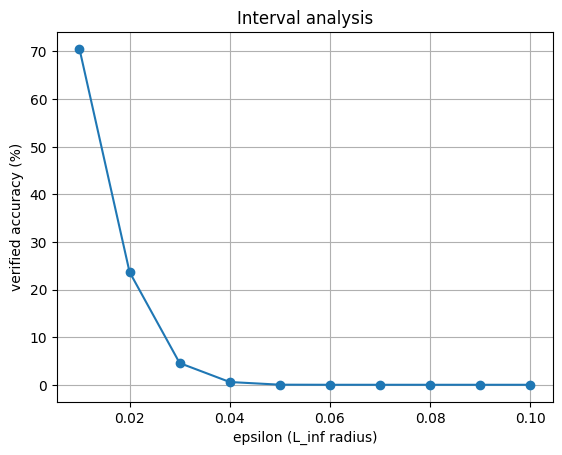

In [11]:
plt.plot(epsilons, results, marker='o')
plt.xlabel('epsilon (L_inf radius)')
plt.ylabel('verified accuracy (%)')
plt.title('Interval analysis')
plt.grid(True)
plt.show()